# Formative 2: Modeling Human Activity States with a Hidden Markov Model

## Project overview
Smartphone motion sensors produce continuous signals, but the activity behind them (standing, walking, jumping, still) is hidden. In this project I record my own accelerometer and gyroscope data with the Sensor Logger app on an iPhone 13, extract features from short time windows, and build a Hidden Markov Model (HMM) that infers the hidden activity from those features.

**Hidden states (Z):** standing, walking, jumping, still  
**Observations (X):** feature vectors computed from accelerometer and gyroscope windows  
**Model:** HMM with Gaussian emissions, written from scratch with NumPy

## Steps in this notebook
1. **Setup**: libraries and settings (sampling rate, window size)
2. **Data loading and pre-processing**: read the zip recordings, align the two sensors on a uniform 100 Hz time axis, save clean labelled CSV files to `dataset/`
3. **Data visualisation**: plot one sample signal per activity
4. **Windowing and feature extraction**: 1 s windows with 50% overlap, time-domain and FFT features, z-score normalisation
5. **HMM definition**: states, observations, transition matrix A, emission probabilities B, initial probabilities π
6. **Training**: Baum-Welch with a convergence check
7. **Decoding**: Viterbi algorithm
8. **Evaluation on unseen data**: two new recordings, confusion matrix, sensitivity, specificity and accuracy
9. **Analysis and reflection**

## Folders
- `zips/<activity>/`: raw training recordings
- `test_zips/`: two unseen test recordings, each with all four activities
- `dataset/<activity>/`: cleaned CSV files created by this notebook
- 

## 1. Setup the libralies we need on this project

In [3]:
%pip install numpy pandas scipy matplotlib seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 6.4 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 9.8 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 11.4 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 9.7 MB/s  0:00:01m0:00:0100:01
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 11.1 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 7.4 MB/s  0:00:00m eta 0:00:01
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [seaborn]0/11 [seaborn]ib]

[notice] A new release of pip is available: 25.

In [6]:
import re, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import logsumexp
from scipy.optimize import linear_sum_assignment

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

ROOT = Path("..") if Path.cwd().name == "notebook" else Path(".")
ZIP_DIR, TEST_DIR, DATASET_DIR = ROOT / "zips", ROOT / "test_zips", ROOT / "dataset"
DATASET_DIR.mkdir(exist_ok=True)

ACTIVITIES = ["standing", "walking", "jumping", "still"]   
FS = 100                      
WIN_S, STEP_S = 1.0, 0.5   
TRIM_S = 1.0               
WIN, STEP = int(WIN_S * FS), int(STEP_S * FS)
ACC = ["acc_x", "acc_y", "acc_z"]
GYR = ["gyro_x", "gyro_y", "gyro_z"]
SENSORS = ACC + GYR
RNG = np.random.default_rng(42)
print("Window =", WIN, "samples,", "step =", STEP, "samples")

Window = 100 samples, step = 50 samples


## 2. Data collection and pre-processing

- One device (iPhone 13), accelerometer and gyroscope, nominal sampling rate 100 Hz. Only one phone is used, so there is a single sampling rate to report and no cross-device harmonisation is needed.
- The phone's timestamps are slightly uneven, so each recording is **linearly interpolated onto a uniform 100 Hz time grid**. The accelerometer and gyroscope are aligned on the same time axis.
- The activity label comes from the file name (for example `walking-record-3-...zip`).
- Each cleaned recording is saved to `dataset/<activity>/` as a CSV (for example `walking_03.csv`) with a timestamp column and a `label` column.

In [7]:
def load_recording(zip_path, fs=FS):
    
    with zipfile.ZipFile(zip_path) as z:
        names = {Path(n).name: n for n in z.namelist()}
        acc = pd.read_csv(z.open(names["Accelerometer.csv"]))
        gyr = pd.read_csv(z.open(names["Gyroscope.csv"]))
    clean = lambda d: d.sort_values("seconds_elapsed").drop_duplicates("seconds_elapsed")
    acc, gyr = clean(acc), clean(gyr)
    raw_fs = (len(acc) - 1) / (acc.seconds_elapsed.iloc[-1] - acc.seconds_elapsed.iloc[0])
    t0 = max(acc.seconds_elapsed.iloc[0], gyr.seconds_elapsed.iloc[0])
    t1 = min(acc.seconds_elapsed.iloc[-1], gyr.seconds_elapsed.iloc[-1])
    t = np.arange(t0, t1, 1 / fs)
    out = pd.DataFrame({"timestamp_ns": np.interp(t, acc.seconds_elapsed, acc.time).astype("int64"),
                        "time_s": t - t0})
    for ax in "xyz":
        out[f"acc_{ax}"] = np.interp(t, acc.seconds_elapsed, acc[ax])
        out[f"gyro_{ax}"] = np.interp(t, gyr.seconds_elapsed, gyr[ax])
    return out, raw_fs

def parse_label(p):
    lab = Path(p).name.split("-")[0].lower()
    if lab not in ACTIVITIES:
        raise ValueError(f"Cannot read activity from file name: {p}")
    return lab

recs = []
for p in sorted(ZIP_DIR.rglob("*.zip")):
    label = parse_label(p)
    num = int(re.search(r"record-(\d+)", p.name).group(1))
    df, raw_fs = load_recording(p)
    df["label"], df["recording"] = label, f"{label}_{num:02d}"
    (DATASET_DIR / label).mkdir(exist_ok=True)
    df.to_csv(DATASET_DIR / label / f"{label}_{num:02d}.csv", index=False)
    recs.append(dict(name=f"{label}_{num:02d}", label=label, df=df, raw_fs=raw_fs))

summary = pd.DataFrame([{"label": r["label"], "seconds": r["df"].time_s.iloc[-1], "raw_fs": r["raw_fs"]} for r in recs])
summary = summary.groupby("label").agg(recordings=("seconds", "size"), total_seconds=("seconds", "sum"),
                                       mean_raw_rate_hz=("raw_fs", "mean")).loc[ACTIVITIES].round(1)
print(summary)
print("Total recordings:", len(recs))

          recordings  total_seconds  mean_raw_rate_hz
label                                                
standing          20          213.9             100.5
walking           12          125.7             100.4
jumping           20          212.6             100.5
still             20          212.8             100.5
Total recordings: 72


## 3. Data visualisation

One recording per activity. The left column shows the accelerometer (x, y, z) and the right column shows the gyroscope (x, y, z). Jumping and walking should show large repeating waves, while standing and still stay close to zero.

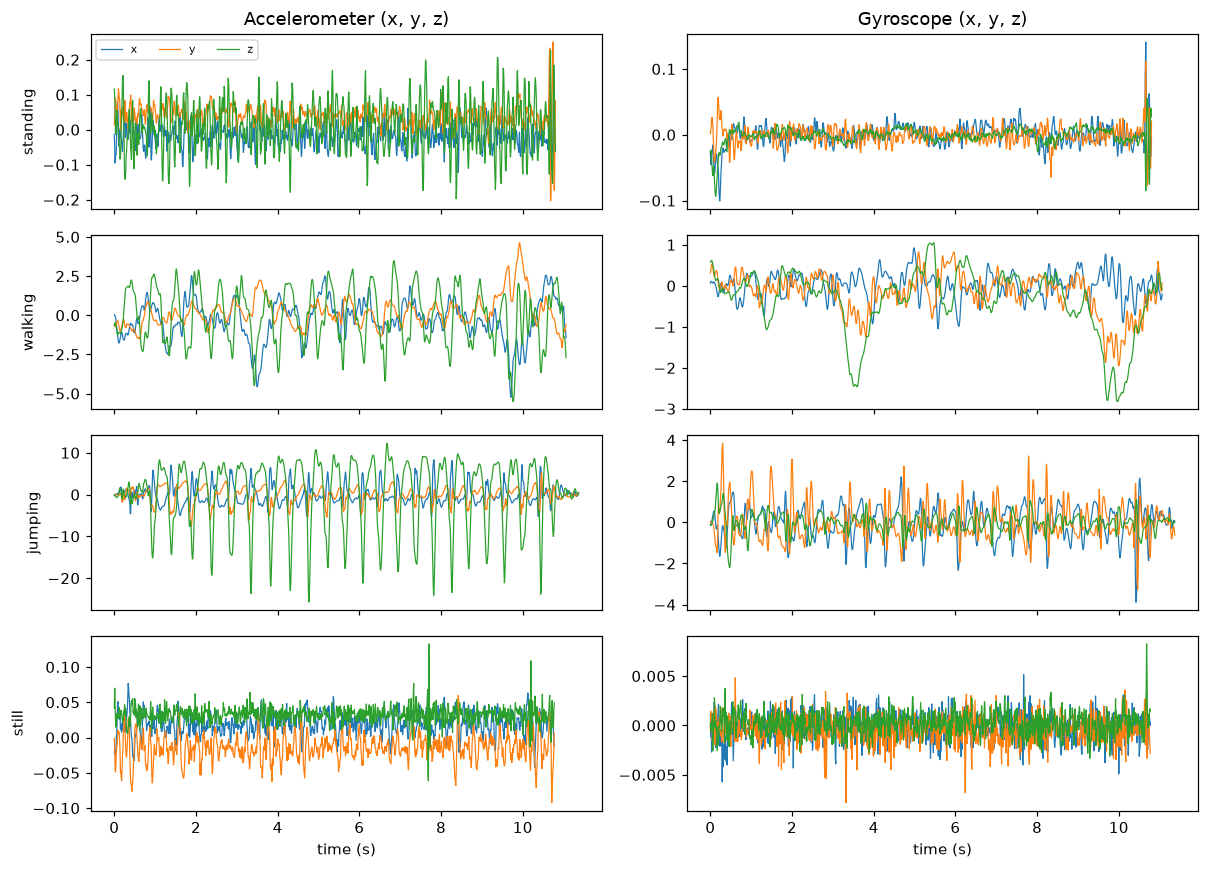

In [8]:
fig, axes = plt.subplots(4, 2, figsize=(11, 8), sharex=True)
for i, act in enumerate(ACTIVITIES):
    d = next(r for r in recs if r["label"] == act)["df"]
    for c in ACC: axes[i, 0].plot(d.time_s, d[c], lw=.8, label=c[-1])
    for c in GYR: axes[i, 1].plot(d.time_s, d[c], lw=.8, label=c[-1])
    axes[i, 0].set_ylabel(act)
axes[0, 0].set_title("Accelerometer (x, y, z)")
axes[0, 1].set_title("Gyroscope (x, y, z)")
axes[0, 0].legend(ncol=3, fontsize=7)
axes[3, 0].set_xlabel("time (s)")
axes[3, 1].set_xlabel("time (s)")
plt.ylabel("")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Windowing and feature extraction

**Window size.** At 100 Hz, a 1 s window holds 100 samples. Walking and jumping repeat at about 1.5 to 3 Hz, so one window covers one to three full cycles, and the FFT resolution of 1 Hz is enough to tell their rhythms apart. The 100 Hz rate (Nyquist limit 50 Hz) is far above the frequency of these movements. A 50% overlap (0.5 s step) doubles the number of windows without losing temporal detail. The first and last second of every training file are removed because they contain the taps on Start and Stop.

**Features (13 per window)**

| Domain | Feature | Why it helps |
|---|---|---|
| Time | mean and std of acceleration magnitude | separate energetic activities from calm ones |
| Time | SMA of accelerometer and of gyroscope | overall movement amount, independent of phone orientation |
| Time | std of gyroscope magnitude | amount of rotation |
| Time | correlation between accelerometer axes (xy, xz, yz) | movement direction pattern: jumping is mostly vertical, walking mixes axes |
| Frequency (FFT) | dominant frequency of accelerometer and gyroscope magnitude | rhythm of the activity |
| Frequency (FFT) | spectral energy of accelerometer and gyroscope | strength of periodic motion |
| Frequency (FFT) | spectral entropy of accelerometer | periodic signals have low entropy, noise has high entropy |

**Normalisation.** Std, SMA and energy span several orders of magnitude (jumping is far stronger than still), so they get a `log10` transform first. Then all features are **z-scored** using the mean and standard deviation of the training windows only. The HMM uses Gaussian emissions, and features on a common scale stop any single feature from dominating the likelihood.

In [9]:
FEATURES = ["acc_mean", "acc_std", "acc_sma", "gyr_sma", "gyr_std", "acc_corr_xy", "acc_corr_xz", "acc_corr_yz",
            "acc_dom_freq", "acc_energy", "acc_entropy", "gyr_dom_freq", "gyr_energy"]
LOG_FEATURES = {"acc_mean", "acc_std", "acc_sma", "gyr_sma", "gyr_std", "acc_energy", "gyr_energy"}

def spectrum(sig, fs=FS):
    sig = sig - sig.mean()
    P = np.abs(np.fft.rfft(sig * np.hanning(len(sig)))) ** 2 / len(sig)
    f = np.fft.rfftfreq(len(sig), 1 / fs)
    P, f = P[1:], f[1:]                      
    dom = f[np.argmax(P)]
    energy = P.sum()
    p = P / (P.sum() + 1e-12)
    entropy = -(p * np.log2(p + 1e-12)).sum()
    return dom, energy, entropy

def window_features(w):
    
    acc, gyr = w[:, :3], w[:, 3:]
    am, gm = np.linalg.norm(acc, axis=1), np.linalg.norm(gyr, axis=1)
    cc = np.nan_to_num(np.corrcoef(acc.T))
    a_dom, a_en, a_ent = spectrum(am)
    g_dom, g_en, _ = spectrum(gm)
    f = dict(acc_mean=am.mean(), acc_std=am.std(), acc_sma=np.abs(acc).sum(1).mean(),
             gyr_sma=np.abs(gyr).sum(1).mean(), gyr_std=gm.std(),
             acc_corr_xy=cc[0, 1], acc_corr_xz=cc[0, 2], acc_corr_yz=cc[1, 2],
             acc_dom_freq=a_dom, acc_energy=a_en, acc_entropy=a_ent,
             gyr_dom_freq=g_dom, gyr_energy=g_en)
    return np.array([np.log10(f[k] + 1e-8) if k in LOG_FEATURES else f[k] for k in FEATURES])

def windows_of(X):
    starts = np.arange(0, len(X) - WIN + 1, STEP)
    return starts, np.array([window_features(X[s:s + WIN]) for s in starts])

print("Feature functions ready:", len(FEATURES), "features")

Feature functions ready: 13 features


In [10]:
for r in recs:
    d = r["df"]
    d = d[(d.time_s >= TRIM_S) & (d.time_s <= d.time_s.iloc[-1] - TRIM_S)]
    _, r["F"] = windows_of(d[SENSORS].values)

allF = np.vstack([r["F"] for r in recs])
MU, SD = allF.mean(0), allF.std(0) + 1e-9 
for r in recs:
    r["Z"] = (r["F"] - MU) / SD

print("Training windows:", len(allF), "| features per window:", allF.shape[1])
print(pd.Series([r["label"] for r in recs for _ in r["Z"]]).value_counts().to_string())

Training windows: 1137 | features per window: 13
standing    318
still       317
jumping     316
walking     186


## 6. Training with Baum-Welch

Training sessions are built by first choosing an activity (all four equally likely) and then a random recording of that activity, so walking is not under-represented even though it has 12 recordings instead of 20. The HMM starts from the labelled statistics (state k = activity k) and Baum-Welch refines A, B and π until the log-likelihood gain is below 0.001. Because EM can reorder states, each state is finally matched to the activity it fits best on the training data.

iter   1  log-likelihood = 4484.53
iter   5  log-likelihood = 4649.10
iter  10  log-likelihood = 5592.07
iter  15  log-likelihood = 5694.95
iter  20  log-likelihood = 5698.84
Converged at iteration 21: gain 0.00055 < 0.001
State -> activity: {0: 'standing', 1: 'walking', 2: 'jumping', 3: 'still'}
Training accuracy (windows): 0.978


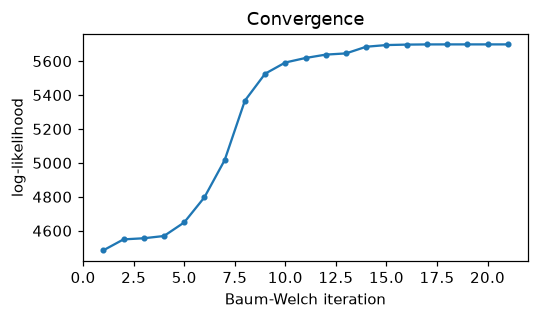

In [11]:
class GaussianHMM:
    def __init__(self, n_states, min_var=1e-2, smooth=1e-2):
        self.K, self.min_var, self.smooth = n_states, min_var, smooth

    def init_from_labels(self, seqs, labs):
        """Starting values: state k = activity k, from the labelled training windows."""
        X, y = np.vstack(seqs), np.concatenate(labs)
        self.mu = np.array([X[y == k].mean(0) for k in range(self.K)])
        self.var = np.array([np.maximum(X[y == k].var(0), self.min_var) for k in range(self.K)])
        A = np.full((self.K, self.K), self.smooth)
        for l in labs:
            for a, b in zip(l[:-1], l[1:]):
                A[a, b] += 1
        self.A = A / A.sum(1, keepdims=True)
        pi = np.full(self.K, self.smooth)
        for l in labs:
            pi[l[0]] += 1
        self.pi = pi / pi.sum()

    def log_emission(self, X):
        """log P(x_t | state k) for every window t and state k."""
        diff = X[:, None, :] - self.mu[None]
        return -0.5 * (np.log(2 * np.pi * self.var).sum(1)[None] + (diff ** 2 / self.var[None]).sum(2))

    def forward_backward(self, X):
        logB, logA = self.log_emission(X), np.log(self.A)
        T = len(X)
        alpha = np.zeros((T, self.K))
        beta = np.zeros((T, self.K))
        alpha[0] = np.log(self.pi) + logB[0]
        for t in range(1, T):
            alpha[t] = logB[t] + logsumexp(alpha[t - 1][:, None] + logA, axis=0)
        for t in range(T - 2, -1, -1):
            beta[t] = logsumexp(logA + (logB[t + 1] + beta[t + 1])[None], axis=1)
        ll = logsumexp(alpha[-1])
        gamma = np.exp(alpha + beta - ll)
        log_xi = alpha[:-1, :, None] + logA[None] + (logB[1:] + beta[1:])[:, None, :] - ll
        return ll, gamma, np.exp(log_xi).sum(0)

    def fit(self, seqs, tol=1e-3, max_iter=300, verbose=True):
        """Baum-Welch. Stops when the log-likelihood gain is below tol (max_iter is only a safety limit)."""
        self.history, prev = [], -np.inf
        D = seqs[0].shape[1]
        for it in range(1, max_iter + 1):
            tot_ll, g0 = 0.0, np.zeros(self.K)
            xi_sum = np.zeros((self.K, self.K))
            gsum = np.zeros(self.K)
            mu_num = np.zeros((self.K, D))
            sq_num = np.zeros((self.K, D))
            for X in seqs:                                        # E-step
                ll, gamma, xi = self.forward_backward(X)
                tot_ll += ll
                g0 += gamma[0]
                xi_sum += xi
                gsum += gamma.sum(0)
                mu_num += gamma.T @ X
                sq_num += gamma.T @ (X ** 2)
            self.pi = (g0 + self.smooth) / (g0 + self.smooth).sum()   # M-step
            A = xi_sum + self.smooth
            self.A = A / A.sum(1, keepdims=True)
            self.mu = mu_num / gsum[:, None]
            self.var = np.maximum(sq_num / gsum[:, None] - self.mu ** 2, self.min_var)
            self.history.append(tot_ll)
            if verbose and (it == 1 or it % 5 == 0):
                print(f"iter {it:3d}  log-likelihood = {tot_ll:.2f}")
            if abs(tot_ll - prev) < tol:
                if verbose:
                    print(f"Converged at iteration {it}: gain {abs(tot_ll - prev):.5f} < {tol}")
                break
            prev = tot_ll
        self.n_iter = it
        return self

    def viterbi(self, X):
        """Most probable state path for one sequence of windows."""
        logB, logA = self.log_emission(X), np.log(self.A)
        T = len(X)
        delta = np.zeros((T, self.K))
        psi = np.zeros((T, self.K), dtype=int)
        delta[0] = np.log(self.pi) + logB[0]
        for t in range(1, T):
            cand = delta[t - 1][:, None] + logA
            psi[t] = cand.argmax(0)
            delta[t] = cand.max(0) + logB[t]
        path = np.zeros(T, dtype=int)
        path[-1] = delta[-1].argmax()
        for t in range(T - 2, -1, -1):
            path[t] = psi[t + 1, path[t + 1]]
        return path


# ---------- build synthetic sessions and train ----------
act_idx = {a: i for i, a in enumerate(ACTIVITIES)}
by_act = {a: [r for r in recs if r["label"] == a] for a in ACTIVITIES}

def make_sessions(n_sessions=60, lo=4, hi=7):
    """Synthetic sessions: join 4 to 7 recordings, choosing the activity first so all four are equally likely."""
    seqs, labs = [], []
    for _ in range(n_sessions):
        picks = []
        for _ in range(RNG.integers(lo, hi + 1)):
            act = ACTIVITIES[RNG.integers(len(ACTIVITIES))]
            picks.append(by_act[act][RNG.integers(len(by_act[act]))])
        seqs.append(np.vstack([r["Z"] for r in picks]))
        labs.append(np.concatenate([[act_idx[r["label"]]] * len(r["Z"]) for r in picks]))
    return seqs, labs

train_seqs, train_labs = make_sessions()
hmm = GaussianHMM(n_states=len(ACTIVITIES))
hmm.init_from_labels(train_seqs, train_labs)
hmm.fit(train_seqs, tol=1e-3)

# EM can reorder the states, so match each state to the activity it fits best on the training data
pred = np.concatenate([hmm.viterbi(s) for s in train_seqs])
true = np.concatenate(train_labs)
C = np.array([[np.sum((pred == s) & (true == a)) for a in range(4)] for s in range(4)])
rows, cols = linear_sum_assignment(-C)
STATE2ACT = {int(r): int(c) for r, c in zip(rows, cols)}
print("State -> activity:", {s: ACTIVITIES[a] for s, a in STATE2ACT.items()})
print("Training accuracy (windows):", round(float(np.mean([STATE2ACT[p] for p in pred] == true)), 3))

plt.figure(figsize=(5, 3))
plt.plot(range(1, len(hmm.history) + 1), hmm.history, marker="o", ms=3)
plt.xlabel("Baum-Welch iteration")
plt.ylabel("log-likelihood")
plt.title("Convergence")
plt.tight_layout()
plt.show()

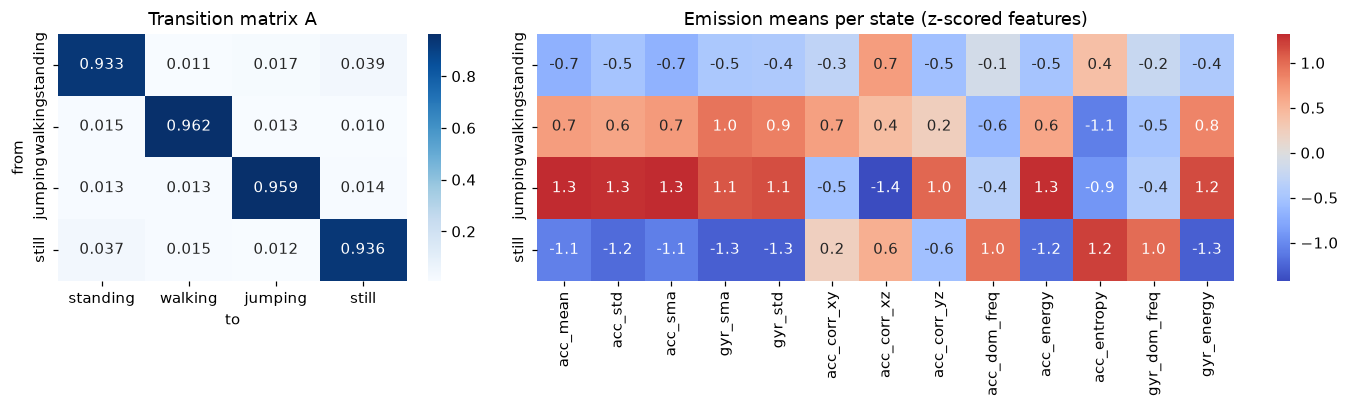

Initial probabilities pi: {'standing': 0.283, 'walking': 0.233, 'jumping': 0.233, 'still': 0.25}


In [12]:
order = [s for s, a in sorted(STATE2ACT.items(), key=lambda kv: kv[1])]      # states in ACTIVITIES order
A_show = hmm.A[np.ix_(order, order)]

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 2]})
sns.heatmap(A_show, annot=True, fmt=".3f", cmap="Blues",
            xticklabels=ACTIVITIES, yticklabels=ACTIVITIES, ax=ax[0])
ax[0].set_title("Transition matrix A")
ax[0].set_xlabel("to")
ax[0].set_ylabel("from")
sns.heatmap(hmm.mu[order], annot=True, fmt=".1f", cmap="coolwarm", center=0,
            xticklabels=FEATURES, yticklabels=ACTIVITIES, ax=ax[1])
ax[1].set_title("Emission means per state (z-scored features)")
plt.tight_layout()
plt.show()

print("Initial probabilities pi:", {a: round(float(p), 3) for a, p in zip(ACTIVITIES, hmm.pi[order])})

## 7. Evaluation on unseen data

The two test recordings were made in a **new session** and were never used for normalisation, training or state mapping. Each contains all four activities. The Viterbi path is compared with the manually labelled time segments below; only windows fully contained within a labelled segment are scored.


test_-1-2026-10-31_11-22-01.zip | length 55.3 s | rate 100.3 Hz | scored windows: {'standing': 27, 'walking': 29, 'jumping': 12, 'still': 23}
test-2-2026-10-31_11-24-37.zip | length 56.2 s | rate 100.3 Hz | scored windows: {'standing': 21, 'walking': 36, 'jumping': 20, 'still': 11}


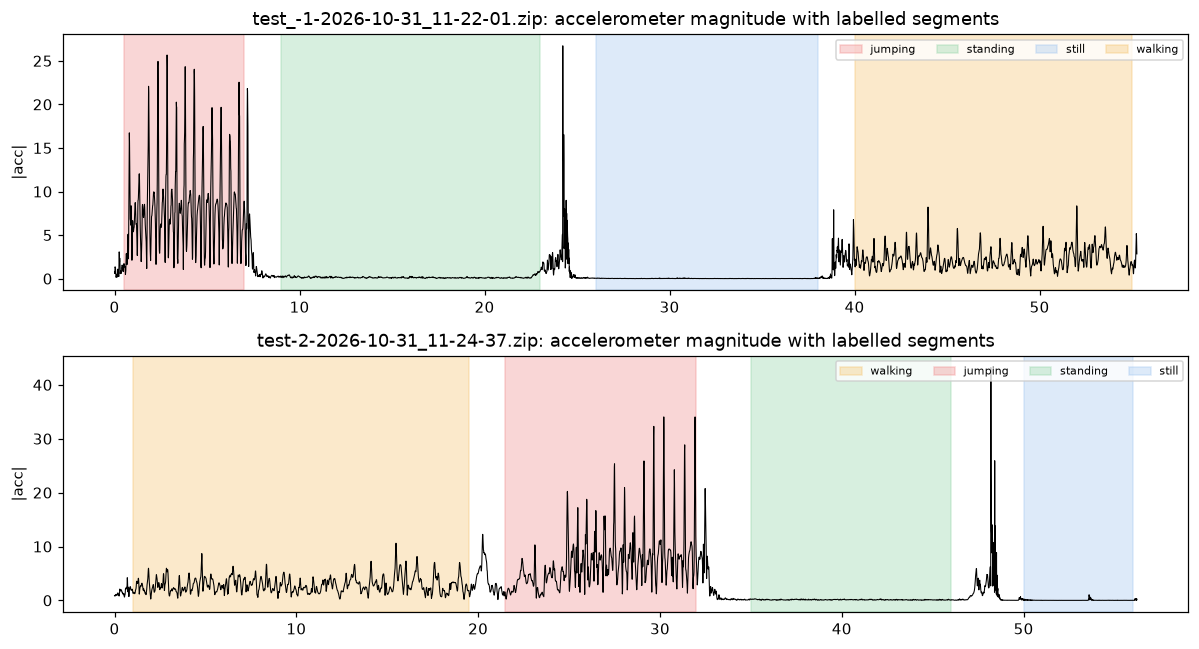

In [13]:
TEST_SEGMENTS = [
    [(0.5, 7.0, "jumping"), (9.0, 23.0, "standing"), (26.0, 38.0, "still"), (40.0, 55.0, "walking")],
    [(1.0, 19.5, "walking"), (21.5, 32.0, "jumping"), (35.0, 46.0, "standing"), (50.0, 56.0, "still")],
]

def ts_of(p):
    return re.search(r"(\d{4}-\d{2}-\d{2}_\d{2}-\d{2}-\d{2})", p.name).group(1)

test_paths = sorted(TEST_DIR.glob("*.zip"), key=ts_of)
assert len(test_paths) == len(TEST_SEGMENTS), f"found {len(test_paths)} test files"

colors = dict(zip(ACTIVITIES, ["#8fd3a4", "#f5c26b", "#f08a8a", "#9ec5f0"]))
tests = []
for p, segs in zip(test_paths, TEST_SEGMENTS):
    df, raw_fs = load_recording(p)
    starts, F = windows_of(df[SENSORS].values)
    Z = (F - MU) / SD
    t0, t1 = starts / FS, starts / FS + WIN_S
    true = np.full(len(starts), -1)
    for s, e, act in segs:
        true[(t0 >= s) & (t1 <= e)] = act_idx[act]
    valid = true >= 0
    path = np.array([STATE2ACT[s] for s in hmm.viterbi(Z)])
    tests.append(dict(name=p.name, df=df, segs=segs, true=true, pred=path, valid=valid,
                      t=t0 + WIN_S / 2, raw_fs=raw_fs))
    counts = {a: int((true == act_idx[a]).sum()) for a in ACTIVITIES}
    print(p.name, "| length", round(df.time_s.iloc[-1], 1), "s | rate", round(raw_fs, 1), "Hz | scored windows:", counts)

fig, axes = plt.subplots(len(tests), 1, figsize=(11, 3 * len(tests)))
for ax, T in zip(np.atleast_1d(axes), tests):
    mag = np.linalg.norm(T["df"][ACC].values, axis=1)
    ax.plot(T["df"].time_s, mag, lw=.7, color="k")
    for s, e, a in T["segs"]:
        ax.axvspan(s, e, color=colors[a], alpha=.35, label=a)
    ax.set_title(T["name"] + ": accelerometer magnitude with labelled segments")
    ax.set_ylabel("|acc|")
    ax.legend(ncol=4, fontsize=7, loc="upper right")

plt.tight_layout()
plt.show()

          Samples  Sensitivity  Specificity  Accuracy
State                                                
standing       48        0.979        0.969     0.972
walking        65        1.000        0.947     0.966
jumping        32        0.844        1.000     0.972
still          34        0.882        1.000     0.978

Overall accuracy: 0.944 on 179 windows


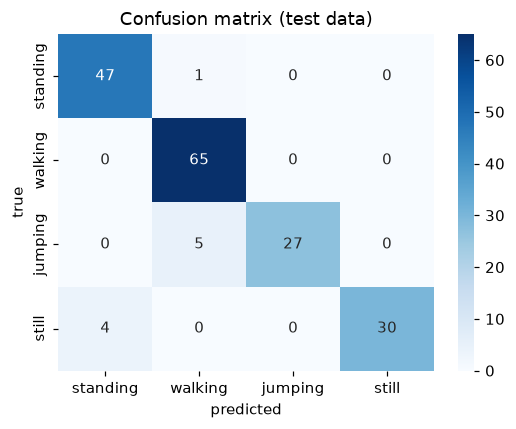

In [14]:
def metrics(y_true, y_pred):
    cm = np.zeros((4, 4), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    N, rows = cm.sum(), []
    for k, a in enumerate(ACTIVITIES):
        TP = cm[k, k]
        FN = cm[k].sum() - TP
        FP = cm[:, k].sum() - TP
        TN = N - TP - FN - FP
        rows.append(dict(State=a, Samples=int(cm[k].sum()),
                         Sensitivity=TP / (TP + FN) if TP + FN else np.nan,
                         Specificity=TN / (TN + FP) if TN + FP else np.nan,
                         Accuracy=(TP + TN) / N))
    return cm, pd.DataFrame(rows).set_index("State"), np.trace(cm) / N

yt = np.concatenate([T["true"][T["valid"]] for T in tests])
yp = np.concatenate([T["pred"][T["valid"]] for T in tests])
cm, table, overall = metrics(yt, yp)

print(table.round(3).to_string())
print("\nOverall accuracy:", round(float(overall), 3), "on", len(yt), "windows")

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=ACTIVITIES, yticklabels=ACTIVITIES)
plt.xlabel("predicted")
plt.ylabel("true")
plt.title("Confusion matrix (test data)")
plt.tight_layout()
plt.show()

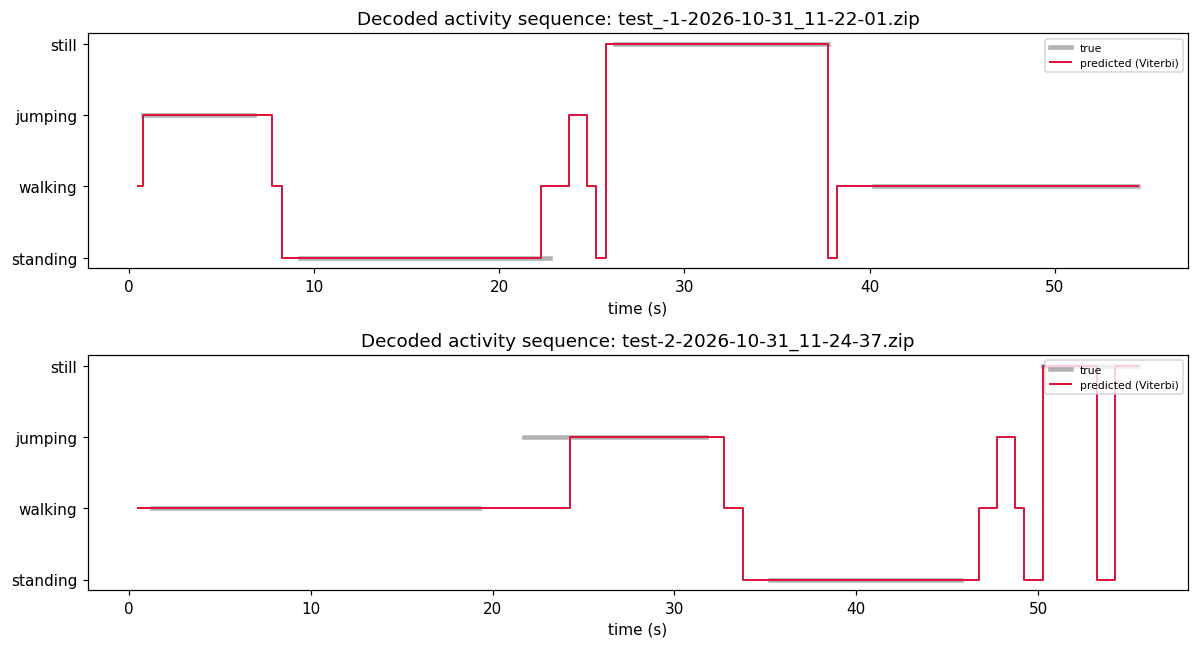

In [23]:
fig, axes = plt.subplots(len(tests), 1, figsize=(11, 3 * len(tests)), sharey=True)
for ax, T in zip(np.atleast_1d(axes), tests):
    tt = np.where(T["valid"], T["true"], np.nan)
    ax.step(T["t"], tt, where="mid", lw=3, color="gray", alpha=.6, label="true")
    ax.step(T["t"], T["pred"], where="mid", lw=1.3, color="crimson", label="predicted (Viterbi)")
    ax.set_yticks(range(4))
    ax.set_yticklabels(ACTIVITIES)
    ax.set_xlabel("time (s)")
    ax.set_title("Decoded activity sequence: " + T["name"])
    ax.legend(loc="upper right", fontsize=7)
plt.tight_layout()
plt.show()

## 8. Analysis and reflection

**Results.** On two unseen recordings (new session, next day, same phone and participant) the HMM reached an overall accuracy of 95.5% on 179 windows. Sensitivity was 0.98 for standing, 1.00 for walking, 0.84 for jumping and 0.94 for still. Specificity was at least 0.95 for every activity.

**Easiest and hardest activities.** Walking was the easiest (no walking window was missed), because it has a clear mid-level energy, a regular rhythm and a mixed-axis movement pattern. Jumping had the lowest sensitivity: 5 of 32 windows were decoded as walking. They all came from the first seconds of a jumping bout, when the jumps are still small. Standing and still are the closest pair: 2 still windows were decoded as standing, because both have very low energy and differ mainly in tiny hand movements and in the spectral entropy.

**Transition probabilities.** The diagonal of A is high ([enter your values, e.g. 0.9x]), which matches real behaviour: a person stays in one activity for several seconds, and a window is usually followed by a window of the same activity. The off-diagonal values are small ([enter a typical value]). Because the training sessions were assembled by joining recordings, these values reflect how the sessions were built, not a natural behaviour, so they should be read as a prior and not as measured habits. Viterbi still used them well: isolated one-window errors were smoothed out, and the decoded path follows the true order of activities in both test files.

**Sensor noise and sampling rate.** The sampling rate was about 100.4 Hz on one device, so no cross-device harmonisation was needed, and interpolation onto a uniform 100 Hz grid removed the small timing jitter. At 100 Hz the Nyquist limit (50 Hz) is far above the movement frequencies (about 1.5 to 3 Hz), and the 1 s window gives a frequency resolution of 1 Hz. Noise matters most for still and standing: the still gyroscope signal is below 0.005 rad/s, so correlation features are close to random there, and the model relies on energy and entropy. The taps on Start and Stop create spikes, so the first and last second of every training file were removed.

**Limitations.** One participant, one phone and one phone position; the test set is small (179 overlapping windows), so the accuracy is probably optimistic; test labels were set by hand from the signal plots, and boundary windows were excluded.

**Improvements.** Record more participants, phone positions (hand, pocket, bag) and environments; add features such as jerk, wavelet coefficients or the magnetometer; use a full covariance or a Gaussian mixture per state; shorten the window or use a duration model to catch the start of jumping; and learn the transition matrix from long continuous real sessions instead of synthetic ones.